In [ ]:
print("Customer Review Sentiment Analysis")
print("Project Started Successfully!")

Customer Review Sentiment Analysis
Project Started Successfully!


In [ ]:
import pandas as pd

data = {
    "review": [
        "The product is excellent and I really loved it",
        "Very good quality, I am happy with this purchase",
        "Amazing product and fast delivery",
        "The product is okay, nothing special",
        "Average quality for the price",
        "I don't like this product",
        "Very poor quality and bad experience",
        "The product was damaged and disappointing"
    ],
    "sentiment": [
        "Positive",
        "Positive",
        "Positive",
        "Neutral",
        "Neutral",
        "Negative",
        "Negative",
        "Negative"
    ]
}

df = pd.DataFrame(data)

df

,review,sentiment
0,The product is excellent and I really loved it,Positive
1,"Very good quality, I am happy with this purchase",Positive
2,Amazing product and fast delivery,Positive
3,"The product is okay, nothing special",Neutral
4,Average quality for the price,Neutral
5,I don't like this product,Negative
6,Very poor quality and bad experience,Negative
7,The product was damaged and disappointing,Negative


In [ ]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text.strip()

df["clean_review"] = df["review"].apply(clean_text)

df[["review", "clean_review", "sentiment"]]

,review,clean_review,sentiment
0,The product is excellent and I really loved it,the product is excellent and i really loved it,Positive
1,"Very good quality, I am happy with this purchase",very good quality i am happy with this purchase,Positive
2,Amazing product and fast delivery,amazing product and fast delivery,Positive
3,"The product is okay, nothing special",the product is okay nothing special,Neutral
4,Average quality for the price,average quality for the price,Neutral
5,I don't like this product,i dont like this product,Negative
6,Very poor quality and bad experience,very poor quality and bad experience,Negative
7,The product was damaged and disappointing,the product was damaged and disappointing,Negative


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder

# Convert text into numerical features
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df["clean_review"])

# Convert sentiment labels into numbers
encoder = LabelEncoder()
y = encoder.fit_transform(df["sentiment"])

# Train the model
model = LogisticRegression()
model.fit(X, y)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
def predict_sentiment(review):
    cleaned = clean_text(review)
    transformed = vectorizer.transform([cleaned])
    prediction = model.predict(transformed)
    return encoder.inverse_transform(prediction)[0]

reviews = [
    "I really love this product",
    "The product is okay",
    "Very bad product and poor quality"
]

for review in reviews:
    print("Review:", review)
    print("Sentiment:", predict_sentiment(review))
    print()

Review: I really love this product
Sentiment: Positive

Review: The product is okay
Sentiment: Neutral

Review: Very bad product and poor quality
Sentiment: Negative



Model Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00         3
     Neutral       1.00      1.00      1.00         2
    Positive       1.00      1.00      1.00         3

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



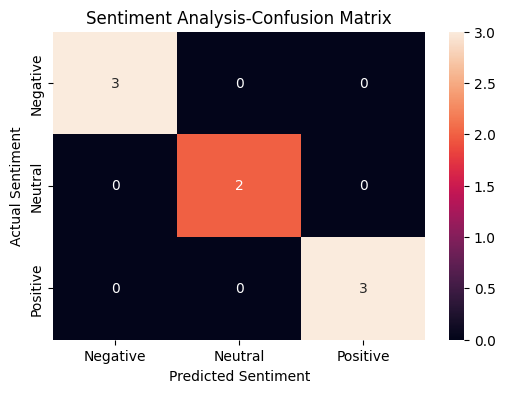

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Predict the training data
y_pred = model.predict(X)

# Calculate accuracy
accuracy = accuracy_score(y, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y, y_pred, target_names=encoder.classes_))

# Confusion Matrix
cm = confusion_matrix(y, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Sentiment Analysis-Confusion Matrix")
plt.show()

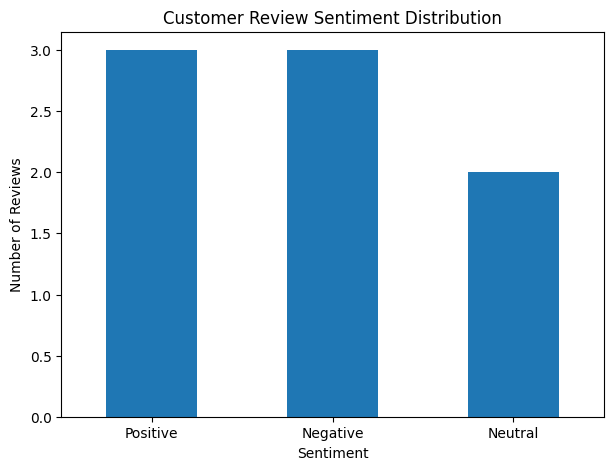

In [ ]:
import matplotlib.pyplot as plt

sentiment_counts = df["sentiment"].value_counts()

plt.figure(figsize=(7, 5))
sentiment_counts.plot(kind="bar")

plt.title("Customer Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"],
    df["sentiment"],
    test_size=0.25,
    random_state=42
)

vectorizer2 = TfidfVectorizer()

X_train_tfidf = vectorizer2.fit_transform(X_train)
X_test_tfidf = vectorizer2.transform(X_test)

model2 = LogisticRegression()
model2.fit(X_train_tfidf, y_train)

y_pred = model2.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", round(accuracy * 100, 2), "%")

Test Accuracy: 0.0 %


In [ ]:
import nltk

nltk.download("movie_reviews")

from nltk.corpus import movie_reviews
import pandas as pd

reviews = []
sentiments = []

for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        reviews.append(movie_reviews.raw(fileid))
        sentiments.append("Positive" if category == "pos" else "Negative")

df = pd.DataFrame({
    "review": reviews,
    "sentiment": sentiments
})

print("Total Reviews:", len(df))
print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

df.head()

[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Unzipping corpora/movie_reviews.zip.


Total Reviews: 2000

Sentiment Distribution:
sentiment
Negative    1000
Positive    1000
Name: count, dtype: int64


,review,sentiment
0,"plot : two teen couples go to a church party ,...",Negative
1,the happy bastard's quick movie review \ndamn ...,Negative
2,it is movies like these that make a jaded movi...,Negative
3,""" quest for camelot "" is warner bros . ' firs...",Negative
4,synopsis : a mentally unstable man undergoing ...,Negative


In [ ]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_review"] = df["review"].apply(clean_text)

print("Text preprocessing completed!")

df[["review", "clean_review", "sentiment"]].head()

Text preprocessing completed!


,review,clean_review,sentiment
0,"plot : two teen couples go to a church party ,...",plot two teen couples go to a church party dri...,Negative
1,the happy bastard's quick movie review \ndamn ...,the happy bastards quick movie review damn tha...,Negative
2,it is movies like these that make a jaded movi...,it is movies like these that make a jaded movi...,Negative
3,""" quest for camelot "" is warner bros . ' firs...",quest for camelot is warner bros first feature...,Negative
4,synopsis : a mentally unstable man undergoing ...,synopsis a mentally unstable man undergoing ps...,Negative


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"],
    df["sentiment"],
    test_size=0.20,
    random_state=42,
    stratify=df["sentiment"]
)

print("Training Reviews:", len(X_train))
print("Testing Reviews:", len(X_test))

# Convert text into numerical features
vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Train the model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Training Reviews: 1600
Testing Reviews: 400
Model training completed successfully!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Predict the test data
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 84.5 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.86      0.82      0.84       200
    Positive       0.83      0.87      0.85       200

    accuracy                           0.84       400
   macro avg       0.85      0.84      0.84       400
weighted avg       0.85      0.84      0.84       400



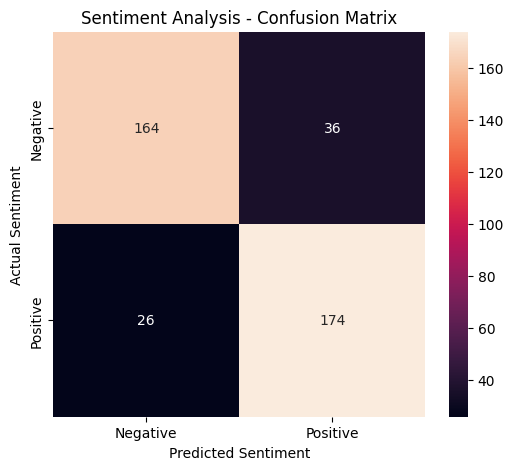

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Sentiment Analysis - Confusion Matrix")

plt.show()

In [ ]:
def predict_sentiment(review):
    cleaned_review = clean_text(review)
    review_tfidf = vectorizer.transform([cleaned_review])

    prediction = model.predict(review_tfidf)[0]

    return prediction


# Test new customer reviews
test_reviews = [
    "I really loved this movie, it was amazing",
    "This movie was boring and disappointing",
    "The movie was okay, but nothing special"
]

for review in test_reviews:
    print("Review:", review)
    print("Predicted Sentiment:", predict_sentiment(review))
    print("-" * 50)

Review: I really loved this movie, it was amazing
Predicted Sentiment: Positive
--------------------------------------------------
Review: This movie was boring and disappointing
Predicted Sentiment: Negative
--------------------------------------------------
Review: The movie was okay, but nothing special
Predicted Sentiment: Negative
--------------------------------------------------


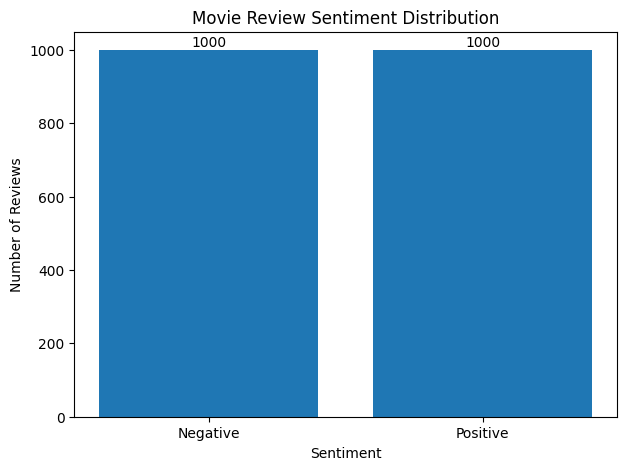

In [ ]:
import matplotlib.pyplot as plt

sentiment_counts = df["sentiment"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(sentiment_counts.index, sentiment_counts.values)

plt.title("Movie Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

for i, value in enumerate(sentiment_counts.values):
    plt.text(i, value + 10, str(value), ha="center")

plt.show()